# 03 · Fill probabilities in the simulated book

How likely is a limit order of 25 shares, posted now at level $j$ behind our touch, to be executed before
the next decision (`dt` = 5)? Measured by posting all candidate levels at once and recording the executed
fraction (D20, D21). Four questions:
1. the vector $\pi_j$ by level, with its error: what `ConstantFill` will use in notebook 04;
2. how $\pi$ depends on order size and step length;
3. whether the paper's nested-fill covariance $\min(\pi_i, \pi_j) − \pi_i \pi_j$ holds for executed fractions;
4. how much of the fill outcome the book state explains: the case for a state-dependent model (notebook 05).

**How one trial works.** With no orders of ours in the book, we take a snapshot and post five limit orders of 25 shares:
one at our own touch (level 0: the best bid if we buy, the best ask if we sell) and one at each of the four ticks behind it.
The market runs for `dt` = 5 time units; we record the fraction of each order that was executed, cancel the rest,
and start again on the other side. These are passive orders only: nothing is posted inside the spread, nothing crosses it.

In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mpc_execution.simulator import SimParams
from mpc_execution.fills import collect_fill_samples, ConstantFill

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
N_LEVELS, QTY, DT, N_TRIALS = 5, 25, 5.0, 2000
params = SimParams()

In [2]:
%%time
df = collect_fill_samples(params, N_LEVELS, QTY, DT, N_TRIALS, seed=0)
wide = df.pivot(index="trial", columns="level", values="filled_frac")
df.head(2 * N_LEVELS)

CPU times: user 9.23 s, sys: 364 ms, total: 9.59 s
Wall time: 9.39 s


,trial,side,level,price,filled_frac,spread,imbalance,depth_at_level,shares_ahead
0,0,BUY,0,10008,0.0,1,0.609890,608,608
1,0,BUY,1,10007,0.0,1,0.609890,209,817
2,0,BUY,2,10006,0.0,1,0.609890,648,1465
3,0,BUY,3,10005,0.0,1,0.609890,24,1489
4,0,BUY,4,10004,0.0,1,0.609890,0,1489
5,1,SELL,0,10009,0.0,1,-0.010458,174,174
6,1,SELL,1,10010,0.0,1,-0.010458,513,687
7,1,SELL,2,10011,0.0,1,-0.010458,86,773
8,1,SELL,3,10012,0.0,1,-0.010458,31,804
9,1,SELL,4,10013,0.0,1,-0.010458,38,842


**Reading the sample.** One row per (trial, level). Trial 0 is a BUY: the best bid is 10008 and holds 608 shares
(`depth_at_level`), so our level-0 order queues behind 608 shares. `shares_ahead` is cumulative: the level-1 order at 10007
has 608 + 209 = 817 shares with price or time priority over it. Level 4 is an empty price (depth 0): our order creates it.
Nothing was executed in this trial: 608 shares is more than twice the market volume that hits one side in a step
(rate 1 × mean size 50 × 5 time units = 250 shares on average). `spread` and `imbalance` describe the book at posting
time, so they are the same in the five rows of a trial.

### 1. Fill probability by level

$\pi_j$ is the average executed fraction at level $j$ over the 2000 trials (D20). The table also splits the outcome into
fully executed, partially executed and untouched: the paper treats a fill as a yes/no event, and we need to know how far
a fraction is from that.

In [3]:
g = df.groupby("level").filled_frac
table = pd.DataFrame({"pi": g.mean(), "se": g.sem(),
                      "P(full)": g.apply(lambda s: (s == 1).mean()),
                      "P(partial)": g.apply(lambda s: s.between(0, 1, inclusive="neither").mean()),
                      "P(zero)": g.apply(lambda s: (s == 0).mean())}).round(3)
table

,pi,se,P(full),P(partial),P(zero)
level,,,,,
0,0.606,0.011,0.576,0.058,0.366
1,0.115,0.007,0.106,0.019,0.874
2,0.037,0.004,0.033,0.008,0.959
3,0.018,0.003,0.016,0.002,0.981
4,0.008,0.002,0.008,0.001,0.992


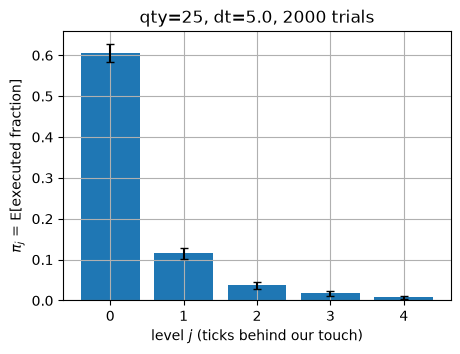

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(table.index, table.pi, yerr=2 * table.se, capsize=3)
ax.set(xlabel="level $j$ (ticks behind our touch)", ylabel=r"$\pi_j$ = E[executed fraction]",
       title=f"qty={QTY}, dt={DT}, {N_TRIALS} trials")
ax.grid()
fig.savefig(FIG / "03_fill_probs.png", dpi=150, bbox_inches="tight"); plt.show()

**Result.** $\pi$ = (0.61, 0.12, 0.04, 0.02, 0.01), each known to ±0.02 or better (2 se).
- The touch fills 61% of the time; one tick behind, 12%; each further tick divides the probability by 2–3.
  This is price priority: level 1 can trade only after everything at the touch is gone (≈275 shares on average, plus our
  own level-0 order), and one step brings only ≈250 shares of market orders against our side.
- Fills are nearly all-or-nothing: at the touch 58% full, 37% nothing, 6% partial. A 25-share order is smaller than
  the typical market order (mean 50), so when the queue reaches us it usually takes all of it.
- Consequence for MPC: the real choice at each step is between paying the spread for certainty (market order) and
  posting at the touch for a 61% chance. Levels 2–4 carry almost no expected quantity; three levels are enough in the QP.

This vector is what `ConstantFill.from_samples(df)` returns and what notebook 04 uses.

### 2. Sensitivity to order size and step length

$\pi$ was measured for one order size (25) and one step length (5). MPC will choose its own quantities, so we need to
know how much $\pi$ moves when they change. 1000 trials per cell: each number is known to about ±0.03 (2 se).
Expected outcome: $\pi$ should increases with `dt`(as more flow arrives) and decreases with `qty` (since a large order is less frequently executed in its entirety)

In [5]:
rows = []
for qty in (10, 25, 50):
    for dt in (2.5, 5.0, 10.0):
        d = collect_fill_samples(params, N_LEVELS, qty, dt, 1000, seed=1)
        pi = d.groupby("level").filled_frac.mean()
        rows.append({"qty": qty, "dt": dt, "pi_0": pi[0], "pi_1": pi[1], "pi_2": pi[2]})
sens = pd.DataFrame(rows).round(3)
sens.pivot(index="qty", columns="dt", values="pi_0")

dt,2.5,5.0,10.0
qty,,,
10,0.329,0.641,0.888
25,0.300,0.596,0.889
50,0.266,0.576,0.865


**Result.** Step length dominates; order size barely matters.
- Doubling `dt` from 2.5 to 5 doubles $\pi_0$ (0.30 → 0.60); at `dt` = 10 the touch fills 89% of the time. This grows
  faster than a memoryless waiting time would (0.30 → 0.51 → 0.76): the queue ahead must be worked through first,
  so the chance of a fill per unit time rises the longer we wait.
- From 10 to 50 shares $\pi_0$ drops by 0.02–0.06, about the size of the error bars: larger orders are completed a
  little less often.
- Consequence: using the $\pi$ measured at 25 shares for whatever quantity the QP chooses is a mild approximation
  between 10 and 50 shares. The step length must instead match the experiment's: $\pi$ belongs to the pair (book, `dt`).

### 3. Is the paper's fill covariance right?

The QP penalises the variance of the quantity executed in a step, which needs the covariance between fills at different
levels. The paper assumes fills are yes/no events and nested (a level fills only if every better level has filled), giving
$\Sigma_{ij} = \min(\pi_i,\pi_j) - \pi_i\pi_j$. Our fills are nested exactly (price priority) but they are fractions.
Two predictions follow, and both can be checked:
- off the diagonal the formula holds exactly: if level $j>i$ received anything, level $i$ is fully executed, so
  $f_i f_j = f_j$ in every trial and $E[f_i f_j] = \pi_j = \min(\pi_i,\pi_j)$;
- on the diagonal it overstates the variance by $E[f_i(1-f_i)]$, which is zero for a yes/no outcome and positive only
  when partial fills occur.

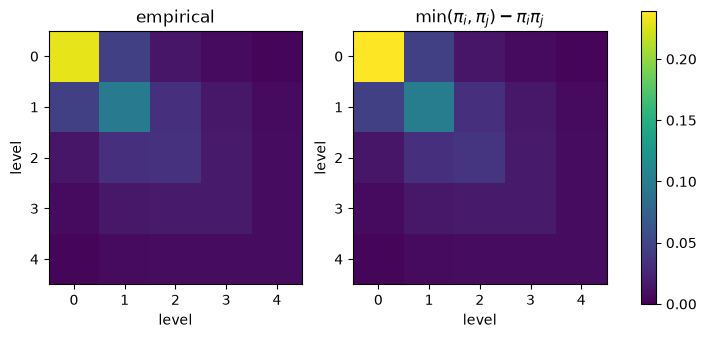

largest off-diagonal difference: 5.551115123125783e-17
diagonal difference: [0.0093 0.0034 0.0016 0.0004 0.0001]
E[f(1-f)] by level : [0.0093 0.0034 0.0016 0.0004 0.0001]
variance of total executed fraction: empirical (measured) 0.703  theory (paper) 0.717


In [6]:
pi = wide.mean().to_numpy()
emp = wide.cov().to_numpy()
theory = np.minimum.outer(pi, pi) - np.outer(pi, pi)       # paper, binary nested fills
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M, name in zip(axes, (emp, theory), ("empirical", r"$\min(\pi_i,\pi_j) − \pi_i \pi_j$")):
    im = ax.imshow(M, vmin=0, vmax=max(emp.max(), theory.max()))
    ax.set(title=name, xlabel="level", ylabel="level")
fig.colorbar(im, ax=axes); fig.savefig(FIG / "03_fill_covariance.png", dpi=150, bbox_inches="tight"); plt.show()

ones = np.ones(N_LEVELS)
emp = wide.cov(ddof=0).to_numpy()
gap = theory - emp
print("largest off-diagonal difference:", np.abs(gap - np.diag(np.diag(gap))).max())
print("diagonal difference:", np.diag(gap).round(4))
print("E[f(1-f)] by level :", (wide * (1 - wide)).mean().to_numpy().round(4))
ones = np.ones(N_LEVELS)
print("variance of total executed fraction: empirical (measured)", round(ones @ emp @ ones, 3), " theory (paper)", round(ones @ theory @ ones, 3))

**Result.** The paper's covariance holds in this book.
- Off the diagonal the two matrices agree to machine precision. This is the nested property, and an independent check
  that the book respects price priority.
- On the diagonal the paper's formula is larger by exactly $\Bbb E[f(1-f)]$, the partial-fill term.
- For the variance of the total executed fraction, the quantity the QP uses, the difference is 2% (0.70 against 0.72),
  because only 6% of touch fills are partial.

The yes/no assumption costs almost nothing here. It would matter for orders large compared with the typical market
order, where partial fills are common, and the correction is known in closed form: subtract $\Bbb E[f(1-f)]$ on the diagonal.

### 4. Does the state of the book change the fill probability?

`ConstantFill` uses $\pi_0$ = 0.61 whatever the book looks like. But a touch order fills only after the shares ahead of it
have traded or been cancelled, and that number varies a lot (608 and 174 in the first two trials above). If the fill
probability depends strongly on it, a constant model is wrong in a predictable direction at every step.
We split the 2000 level-0 orders into ten equal-size groups by `shares_ahead` and look at the executed fraction in each.

Expectation: a steep, downward-sloping curve for `shares_ahead`; the dashed line represents what the constant model assumes for all cases. The further the curve deviates from this line, the greater the error (or "discard") in the constant model.

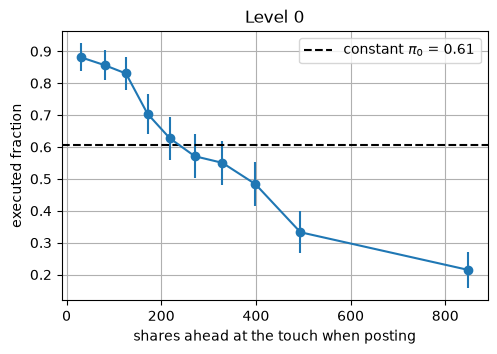

               mean    sem  count
spread_group                     
1             0.613  0.011   1895
2             0.469  0.053     87
3+            0.444  0.121     18
       mean    sem
side              
BUY   0.619  0.015
SELL  0.592  0.015


In [7]:
lvl0 = df[df.level == 0].copy()
lvl0["bin"] = pd.qcut(lvl0.shares_ahead, 10)
curve = lvl0.groupby("bin", observed=True).filled_frac.agg(["mean", "sem", "count"])
mid = [b.mid for b in curve.index]
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.errorbar(mid, curve["mean"], yerr=2 * curve["sem"], marker="o")
ax.axhline(pi[0], ls="--", color="k", label=fr"constant $\pi_0$ = {pi[0]:.2f}")
ax.set(xlabel="shares ahead at the touch when posting", ylabel="executed fraction", title="Level 0")
ax.grid()
ax.legend(); fig.savefig(FIG / "03_fill_vs_queue.png", dpi=150, bbox_inches="tight"); plt.show()


lvl0["spread_group"] = lvl0.spread.clip(upper=3).map({1: "1", 2: "2", 3: "3+"})
print(lvl0.groupby("spread_group").filled_frac.agg(["mean", "sem", "count"]).round(3))
print(lvl0.groupby("side").filled_frac.agg(["mean", "sem"]).round(3))

**Result.** The fill probability at the touch falls from 0.88 with ≈30 shares ahead to 0.21 with ≈850. The constant 0.61
is right only for a queue of ≈250 shares, the average market volume against one side in a step: a shorter queue is
usually cleared, a longer one usually is not.
- Short queue (under ≈150 shares, 3 trials in 10): true probability ≈0.85. A policy assuming 0.61 expects too few fills,
  posts more than it needs and ends the step ahead of schedule.
- Long queue (over ≈450 shares, 2 trials in 10): true probability 0.2–0.35. The policy expects 0.61, gets about half of
  that, falls behind, and has to catch up with market orders.

Both errors are predictable from a number visible in the book before posting.

**Spread.** One tick (95% of trials): 61%. Two ticks: 47% ± 11% (87 trials). With a two-tick spread the next limit order
arriving one tick from the opposite best lands inside the spread, at a better price than ours: we are no longer at the
touch. Three ticks or more are too rare here to say anything.

**Side.** BUY 0.62, SELL 0.59; the difference, 0.03 ± 0.04 (2 se), is compatible with zero, as it must be in a symmetric flow.

In [8]:
bin_mean = lvl0.groupby("bin", observed=True).filled_frac.transform("mean")   # each trial gets its group's average
r2 = bin_mean.var(ddof=0) / lvl0.filled_frac.var(ddof=0)
print(f"fraction of variance explained by shares_ahead deciles: {r2:.2f}")

fraction of variance explained by shares_ahead deciles: 0.19


**How much is that?** Replacing the constant 0.61 with the average of the trial's group removes 19% of the variance of
the outcome. The other 81% is the randomness of the order flow during the step, which no model can see in advance.
A fill stays close to a coin toss; knowing the queue turns a 61/39 coin into one that ranges from 88/12 to 21/79.

In [9]:
lvl0["own_side_imbalance"] = lvl0.imbalance * lvl0.side.map({"BUY": 1, "SELL": -1})
lvl0["imb_group"] = pd.qcut(lvl0.own_side_imbalance, 5)
lvl0.groupby("imb_group", observed=True).agg(filled=("filled_frac", "mean"), shares_ahead=("shares_ahead", "mean")).round(2)

,filled,shares_ahead
imb_group,,
"(-0.985, -0.264]",0.76,141.56
"(-0.264, -0.0754]",0.64,257.29
"(-0.0754, 0.078]",0.60,285.67
"(0.078, 0.261]",0.53,339.23
"(0.261, 0.968]",0.50,375.56


## Conclusions

1. **Fill probabilities** for 25 shares over one step of 5: $\pi$ = (0.61, 0.12, 0.04, 0.02, 0.01) from the touch
   backwards. Fills are close to all-or-nothing (6% partial at the touch). Only the touch carries real quantity.
2. **Sensitivity**: $\pi_0$ is 0.30 / 0.60 / 0.89 for steps of 2.5 / 5 / 10, and moves by at most 0.06 between 10 and 50 shares.
3. **Covariance**: the paper's nested formula is exact off the diagonal and overstates the diagonal by $\Bbb E[f(1-f)]$;
   the variance of the total executed quantity differs by 2%. The paper's $\Sigma$ can be used as is.
4. **State dependence**: at the touch the fill probability falls from 0.88 to 0.21 as the queue ahead grows from ≈30 to
   ≈850 shares; ten groups of that one number explain 19% of the outcome variance. A constant $\pi$ is right on average
   and wrong at almost every step, in a direction the book shows beforehand.

Next: notebook 04 runs MPC with the constant vector of point 1 against the crossing baseline, on the same seeds.
Notebook 05 replaces it with a model of $\pi$ given `shares_ahead`, `spread` and imbalance, and measures what that buys
in schedule deviation and cost.